# 3.线性神经网络

回归（regression）是能为一个或多个自变量与因变量之间关系建模的一类方法。在自然科学和社会科学领域，回归经常用来表示输入和输出之间的关系。

## 3.1 线性回归（linear regression）

### 术语

- 训练数据集（training data set）或训练集（training set）
- 数据集的每行数据称为样本（sample），也可以称为数据点（datapoint）或数据样本（data instance）
- 把试图预测的目标称为标签（label）或目标（target）
- 预测所依据的自变量称为特征（feature）或协变量（covariate）

通常，我们使用n来表示数据集中的样本数。
对索引为i的样本，其输入表示为$x^{(i)}=[x^{(i)}_1,x^{(i)}_2 ]^⊤$，其对应的标签是$y^{(i)}$。

### 线性模型
线性假设是指目标（房屋价格）可以表示为特征（面积和房龄）的加权和，如下面的式子：

$price = w_{area} · area + w_{age} · age + b$ 

$w_{area}$和$w_{age}$ 称为权重（weight），权重决定了每个特征对我们预测值的影响。b称为偏置（bias）、偏移量（offset）或截距（intercept）。偏置是指当所有特征都取值为0时，预测值应该为多少。 
如果没有偏置项，我们模型的表达能力将受到限制。 
严格来说，上面的式子是输入特征的一个仿射变换（affine transformation）。仿射变换的特点是通过加权和对特征进行线性变换（linear transformation），并通过偏置项来进行平移（translation）。

### 损失函数

在我们开始考虑如何用模型拟合（fit）数据之前，我们需要确定一个拟合程度的度量。 损失函数（loss function）能够量化目标的实际值与预测值之间的差距。  
通常我们会选择非负数作为损失，且数值越小表示损失越小，完美预测时的损失为0。 回归问题中最常用的损失函数是平方误差函数。  

由于平方误差函数中的二次方项， 估计值和观测值之间较大的差异将导致更大的损失。   

为了度量模型在整个数据集上的质量，我们需计算在训练集n个样本上的损失均值（也等价于求和）。


在训练模型时，我们希望寻找一组参数（$w^*$, $b^*$）， 这组参数能最小化在所有训练样本上的总损失。

#### 解析解
线性回归刚好是一个很简单的优化问题。 与我们将在本书中所讲到的其他大部分模型不同，线性回归的解可以用一个公式简单地表达出来， 这类解叫作解析解（analytical solution）。  


#### 随机梯度下降
即使在我们无法得到解析解的情况下，我们仍然可以有效地训练模型。 在许多任务上，那些难以优化的模型效果要更好。 因此，弄清楚如何训练这些难以优化的模型是非常重要的。  
一种名为梯度下降（gradient descent）的方法， 这种方法几乎可以优化所有深度学习模型。 它通过不断地在损失函数递减的方向上更新参数来降低误差。  
梯度下降最简单的用法是计算损失函数（数据集中所有样本的损失均值） 关于模型参数的导数（在这里也可以称为梯度）。 但实际中的执行可能会非常慢：因为在每一次更新参数之前，我们必须遍历整个数据集。 因此，我们通常会在每次需要计算更新的时候随机抽取一小批样本， 这种变体叫做小批量随机梯度下降（minibatch stochastic gradient descent）。


批量大小和学习率的值通常是手动预先指定，而不是通过模型训练得到的。   
这些可以调整但不在训练过程中更新的参数称为超参数（hyperparameter）。   

调参（hyperparameter tuning）是选择超参数的过程。  

超参数通常是我们根据训练迭代结果来调整的， 而训练迭代结果是在独立的验证数据集（validation dataset）上评估得到的。

#### 用模型进行预测
给定特征估计目标的过程通常称为预测（prediction）

#### 矢量化加速
在训练我们的模型时，我们经常希望能够同时处理整个小批量的样本。 为了实现这一点，需要我们对计算进行矢量化， 从而利用线性代数库，而不是在Python中编写开销高昂的for循环。

In [195]:
%matplotlib inline
import math
import time
import numpy as np
import torch
from d2l import torch as d2l

In [196]:
n = 10000  # 样本数
a = torch.ones([n]) 
b = torch.ones([n]) 

In [197]:
class Timer: #@save
    """记录多次运行时间"""
    def __init__(self):
        self.times = []
        self.start()

    def start(self):
        """启动计时器"""
        self.tik = time.time()

    def stop(self):
        """停止计时器并将时间记录在times中"""
        self.times.append(time.time() - self.tik)
        return self.times[-1]

    def avg(self):
        """返回平均时间"""
        return sum(self.times) / len(self.times)

    def sum(self):
        """返回总时间"""
        return sum(self.times)

    def cumsum(self):
        """返回累计时间"""
        return np.array(self.times).cumsum().tolist()

现在我们可以对工作负载进行基准测试。

In [198]:
c = torch.zeros(n) # for循环的开销
timer = Timer()
for i in range(n):
    c[i] = a[i] + b[i]
f'{timer.stop():.5f} sec'

'0.05865 sec'

In [199]:
timer.start()
d = a + b  #  矢量化代码通常会带来数量级的加速。
f'{timer.stop():.5f} sec'

'0.00049 sec'

#### 正态分布与平方损失

正态分布和线性回归之间的关系很密切。 正态分布（normal distribution），也称为高斯分布（Gaussian distribution）

In [200]:
def normal(x, mu, sigma):
    p = 1 / math.sqrt(2 * math.pi * sigma**2)
    return p * np.exp(-0.5 / sigma**2 * (x - mu)**2)

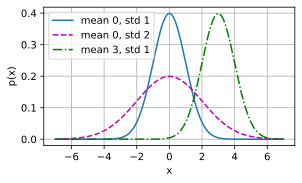

In [201]:
x = np.arange(-7, 7, 0.01)
params = [(0, 1), (0, 2), (3, 1)]
d2l.plot(x, [normal(x, mu, sigma) for mu, sigma in params], xlabel='x', ylabel='p(x)', figsize=(4.5, 2.5), legend=[f'mean {mu}, std {sigma}' for mu, sigma in params])

改变均值会产生沿x轴的偏移，增加方差将会分散分布、降低其峰值。

注：  
在线性网络（尤其是线性回归）中，正态分布负责描述数据中的噪声，最大似然估计负责确定模型参数。它们共同解释了：为什么线性回归通常使用均方误差作为损失函数。

### 3.1.4 从线性回归到深度网络

输入层中的输入数（或称为特征维度，feature dimensionality）为d。   
网络的输出为 $O_1$，因此输出层中的输出数是1。   
需要注意的是，输入值都是已经给定的，并且只有一个**计算**神经元。  
由于模型重点在发生计算的地方，所以通常我们在计算层数时不考虑输入层。  
也就是说，线性回归模型神经网络的层数为1。  
我们可以将线性回归模型视为仅由单个人工神经元组成的神经网络，或称为单层神经网络。

对于线性回归，每个输入都与每个输出（在本例中只有一个输出）相连， 我们将这种变换称为全连接层（fully-connected layer）或称为稠密层（dense layer）。

#### 生物学

线性回归发明的时间（1795年）早于计算神经科学，所以将线性回归描述为神经网络似乎不合适。  

当今大多数深度学习的研究几乎没有直接从神经科学中获得灵感。 

如今在深度学习中的灵感同样或更多地来自数学、统计学和计算机科学。

## 3.2 线性回归的从零开始实现

在这一节中，我们将从零开始实现整个方法， 包括数据流水线、模型、损失函数和小批量随机梯度下降优化器。 

In [202]:
%matplotlib inline
import random
import torch
from d2l import torch as d2l


### 3.2.1  生成数据集

In [203]:
def synthetic_data(w, b, num_examples): #@save
    """生成y = Xw + b + 噪声"""
    X = torch.normal(0, 1, (num_examples, len(w)))
    y = torch.matmul(X, w) + b
    y += torch.normal(0, 0.01, y.shape)
    return X, y.reshape((-1, 1))

true_w = torch.tensor([2, -3.4])
true_b = 4.2
features, labels = synthetic_data(true_w, true_b, 1000)

In [204]:
print('features:', features[0], '\nlabel:', labels[0])

features: tensor([-0.9321,  0.5545]) 
label: tensor([0.4502])


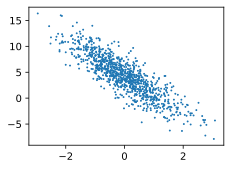

In [205]:
d2l.set_figsize()
d2l.plt.scatter(features[:, 1].detach().numpy(), labels.detach().numpy(), 1);

### 3.2.2. 读取数据集

In [206]:
def data_iter(batch_size, features, labels):
    print('features:', features[0], '\nlabel:', labels[0])
    num_examples = len(features)
    indices = list(range(num_examples))
    # 这些样本是随机读取的， 没有特定的顺序
    random.shuffle(indices)
    for i in range(0, num_examples, batch_size):
        batch_indices = torch.tensor(indices[i: min(i + batch_size, num_examples)])
        yield features[batch_indices], labels[batch_indices]

In [207]:
batch_size = 10

for X, y in data_iter(batch_size, features, labels):
    print(X, '\n', y)
    break

features: tensor([-0.9321,  0.5545]) 
label: tensor([0.4502])
tensor([[ 0.5715, -0.1705],
        [ 0.3309, -1.3141],
        [ 0.6583,  0.5813],
        [ 0.2655, -0.3612],
        [ 0.0819, -0.5666],
        [-0.0337,  0.8965],
        [-0.5406, -0.5865],
        [ 0.9181,  0.5830],
        [-0.5123, -0.1923],
        [-0.0569,  0.5229]]) 
 tensor([[5.8979],
        [9.3592],
        [3.5365],
        [5.9587],
        [6.2861],
        [1.0838],
        [5.0957],
        [4.0645],
        [3.8098],
        [2.2954]])


In [208]:
#检查数据的整体情况
print(features.mean(dim=0))
print(features.std(dim=0))
print((features < 0).float().mean(dim=0))

tensor([ 0.0115, -0.0178])
tensor([0.9779, 0.9677])
tensor([0.4990, 0.5180])


开始用小批量随机梯度下降优化我们的模型参数之前， 我们需要先有一些参数。 在下面的代码中，我们通过从均值为0、标准差为0.01的正态分布中采样随机数来初始化权重， 并将偏置初始化为0。

In [209]:
w = torch.normal(0, 0.01, size=(2,1), requires_grad=True)
b = torch.zeros(1, requires_grad=True)

在初始化参数之后，我们的任务是更新这些参数，直到这些参数足够拟合我们的数据。 每次更新都需要计算损失函数关于模型参数的梯度。  
有了这个梯度，我们就可以向减小损失的方向更新每个参数。

### 3.2.4. 定义模型

In [210]:
def linreg(X, w, b):  #@save
    """线性回归模型"""
    return torch.matmul(X, w) + b

### 3.2.5. 定义损失函数

因为需要计算损失函数的梯度，所以我们应该先定义损失函数。 这里我们使用 3.1节中描述的平方损失函数。 在实现中，我们需要将真实值y的形状转换为和预测值y_hat的形状相同。

In [211]:
def squared_loss(y_hat, y):  #@save
    """均方损失"""
    return (y_hat - y.reshape(y_hat.shape)) ** 2 / 2

### 3.2.6. 定义优化算法

正如我们在 3.1节中讨论的，线性回归有解析解。 尽管线性回归有解析解，但本书中的其他模型却没有。 这里我们介绍小批量随机梯度下降。

在每一步中，使用从数据集中随机抽取的一个小批量，然后根据参数计算损失的梯度。 接下来，朝着减少损失的方向更新我们的参数。 下面的函数实现小批量随机梯度下降更新。 该函数接受模型参数集合、学习速率和批量大小作为输入。每 一步更新的大小由学习速率lr决定。 因为我们计算的损失是一个批量样本的总和，所以我们用批量大小（batch_size） 来规范化步长，这样步长大小就不会取决于我们对批量大小的选择。

In [212]:
def sgd(params, lr, batch_size):  #@save
    """小批量随机梯度下降"""
    with torch.no_grad():
        for param in params:
            param -= lr * param.grad / batch_size
            param.grad.zero_()

### 3.2.7. 训练

现在我们已经准备好了模型训练所有需要的要素，可以实现主要的训练过程部分了。  
理解这段代码至关重要，因为从事深度学习后， 相同的训练过程几乎一遍又一遍地出现。 在每次迭代中，我们读取一小批量训练样本，并通过我们的模型来获得一组预测。 计算完损失后，我们开始反向传播，存储每个参数的梯度。 最后，我们调用优化算法sgd来更新模型参数。

在每个迭代周期（epoch）中，我们使用data_iter函数遍历整个数据集， 并将训练数据集中所有样本都使用一次（假设样本数能够被批量大小整除）。  
这里的迭代周期个数num_epochs和学习率lr都是超参数，分别设为3和0.03。   
设置超参数很棘手，需要通过反复试验进行调整。 我们现在忽略这些细节，以后会在 11节中详细介绍。

In [213]:
lr = 0.03
num_epochs = 10
net = linreg
loss = squared_loss

for epoch in range(num_epochs):
    for X, y in data_iter(batch_size, features, labels):
        l = loss(net(X, w, b), y)  # X和y的小批量损失
        # 因为l形状是(batch_size,1)，而不是一个标量。l中的所有元素被加到一起，
        # 并以此计算关于[w,b]的梯度
        l.sum().backward()
        #sgd([w, b], lr, batch_size)  # 使用随机梯度下降算法参数的梯度更新参数
        sgd([w, b], lr, X.shape[0]) #最后一个批次可能不足 batch_size，这是更严谨的写法
    with torch.no_grad():
        train_l = loss(net(features, w, b), labels)
        print(f'epoch {epoch + 1}, loss {float(train_l.mean()):f}')

features: tensor([-0.9321,  0.5545]) 
label: tensor([0.4502])
epoch 1, loss 0.036623
features: tensor([-0.9321,  0.5545]) 
label: tensor([0.4502])
epoch 2, loss 0.000137
features: tensor([-0.9321,  0.5545]) 
label: tensor([0.4502])
epoch 3, loss 0.000053
features: tensor([-0.9321,  0.5545]) 
label: tensor([0.4502])
epoch 4, loss 0.000053
features: tensor([-0.9321,  0.5545]) 
label: tensor([0.4502])
epoch 5, loss 0.000053
features: tensor([-0.9321,  0.5545]) 
label: tensor([0.4502])
epoch 6, loss 0.000053
features: tensor([-0.9321,  0.5545]) 
label: tensor([0.4502])
epoch 7, loss 0.000053
features: tensor([-0.9321,  0.5545]) 
label: tensor([0.4502])
epoch 8, loss 0.000053
features: tensor([-0.9321,  0.5545]) 
label: tensor([0.4502])
epoch 9, loss 0.000053
features: tensor([-0.9321,  0.5545]) 
label: tensor([0.4502])
epoch 10, loss 0.000053


In [214]:
print(f'w的估计误差: {true_w - w.reshape(true_w.shape)}')
print(f'b的估计误差: {true_b - b}')

w的估计误差: tensor([ 0.0003, -0.0008], grad_fn=<SubBackward0>)
b的估计误差: tensor([-2.9564e-05], grad_fn=<RsubBackward1>)


因为我们使用的是自己合成的数据集，所以我们知道真正的参数是什么。 因此，我们可以通过比较真实参数和通过训练学到的参数来评估训练的成功程度。 事实上，真实参数和通过训练学到的参数确实非常接近。  

注意，我们不应该想当然地认为我们能够完美地求解参数。 在机器学习中，我们通常不太关心恢复真正的参数，而更关心如何高度准确预测参数。 幸运的是，即使是在复杂的优化问题上，随机梯度下降通常也能找到非常好的解。 其中一个原因是，在深度网络中存在许多参数组合能够实现高度精确的预测。  

注：
深度网络中往往存在许多能够产生准确预测的参数组合，所以 SGD 不需要找到某个唯一的点，只需要进入某个表现良好的低损失区域。

“SGD 通常能找到好解”是一种实践经验，并非无条件保证。它仍然受到以下因素影响：
网络结构；
参数初始化；
学习率；
优化器；
数据质量；
训练时间。

## 3.3. 线性回归的简洁实现

许多公司、学者和业余爱好者开发了各种成熟的开源框架。  

这些框架可以自动化基于梯度的学习算法中重复性的工作。   
在 3.2节中，我们只运用了：   
- （1）通过张量来进行数据存储和线性代数；  
- （2）通过自动微分来计算梯度。   

实际上，由于数据迭代器、损失函数、优化器和神经网络层很常用， 现代深度学习库也为我们实现了这些组件。

也就是说，利用深度学习框架（常见的有pytorch、tensorflow、MXNET、PADDLE），我们可以以更简洁的方式实现线性回归。

In [215]:
import numpy as np
import torch
from torch.utils import data
from d2l import torch as d2l

true_w = torch.tensor([2, -3.4])
true_b = 4.2
features, labels = d2l.synthetic_data(true_w, true_b, 1000)


### 3.3.2 读取数据集  

In [216]:
def load_array(data_arrays, batch_size, is_train=True):  #@save  
    """构造一个PyTorch数据迭代器"""  
    dataset = data.TensorDataset(*data_arrays)  
    return data.DataLoader(dataset, batch_size, shuffle=is_train)  

batch_size = 10  
data_iter = load_array((features, labels), batch_size)  

next(iter(data_iter))  # 返回一个batch的特征和标签

[tensor([[-0.2344, -0.3228],
         [ 0.3432, -1.4514],
         [-0.7066, -1.9300],
         [-0.5189,  1.7394],
         [-2.7648, -0.8436],
         [ 1.3722,  0.3461],
         [ 1.6490,  1.1126],
         [ 0.1633, -1.5979],
         [ 0.7580, -1.5405],
         [ 0.9822,  0.8318]]),
 tensor([[ 4.8195],
         [ 9.8060],
         [ 9.3467],
         [-2.7736],
         [ 1.5299],
         [ 5.7519],
         [ 3.7321],
         [ 9.9556],
         [10.9411],
         [ 3.3432]])]

### 3.3.3 定义模型

In [217]:
from torch import nn
net = nn.Sequential(nn.Linear(2, 1)) #第一个参数是输入特征的形状；第二个指定输出特征的形状，这里输出是个标量

### 3.3.4. 初始化模型参数  
深度学习框架通常有预定义的方法来初始化参数。   
在这里，我们指定每个权重参数应该从均值为0、标准差为0.01的正态分布中随机采样， 偏置参数将初始化为零。  

正如我们在构造nn.Linear时指定输入和输出尺寸一样， 现在我们能直接访问参数以设定它们的初始值。 我们通过net[0]选择网络中的第一个图层， 然后使用weight.data和bias.data方法访问参数。 我们还可以使用替换方法normal_和fill_来重写参数值。

In [218]:
#net[0].weight.data.normal_(0, 0.01) #旧写法
#net[0].bias.data.fill_(0)  #旧写法

layer0 = net[0]
assert isinstance(layer0, nn.Linear)

#PyTorch 官方说明，torch.nn.init 中的初始化函数本身就在 no_grad 模式下执行，所以不会被自动微分记录
nn.init.normal_(layer0.weight, mean = 0, std =  0.01)

if layer0.bias is not None:
    nn.init.zeros_(layer0.bias)




### 3.3.5 定义损失函数
计算均方误差使用的是MSELoss类，也称为平方$L_2$范数。 默认情况下，它返回所有样本损失的平均值。

In [219]:
loss = nn.MSELoss()

### 3.3.6 定义优化算法

小批量随机梯度下降算法是一种优化神经网络的标准工具， PyTorch在optim模块中实现了该算法的许多变种。 当我们实例化一个SGD实例时，我们要指定优化的参数 （可通过net.parameters()从我们的模型中获得）以及优化算法所需的超参数字典。 小批量随机梯度下降只需要设置lr值，这里设置为0.03。

In [220]:
trainer = torch.optim.SGD(net.parameters(), lr=0.03)

### 3.3.7. 训练

通过深度学习框架的高级API来实现我们的模型只需要相对较少的代码。 我们不必单独分配参数、不必定义我们的损失函数，也不必手动实现小批量随机梯度下降。 当我们需要更复杂的模型时，高级API的优势将大大增加。 当我们有了所有的基本组件，训练过程代码与我们从零开始实现时所做的非常相似。

每个迭代周期里，我们将完整遍历一次数据集（train_data）， 不停地从中获取一个小批量的输入和相应的标签。 对于每一个小批量，我们会进行以下步骤:

- 通过调用net(X)生成预测并计算损失l（前向传播）。

- 通过进行反向传播来计算梯度。

- 通过调用优化器来更新模型参数。

为了更好的衡量训练效果，我们计算每个迭代周期后的损失，并打印它来监控训练过程。

In [221]:
num_epochs = 3
for epoch in range(num_epochs):
    for X, y in data_iter:
        l = loss(net(X), y)  # X和y的小批量损失
        trainer.zero_grad()  # 梯度清零
        l.backward()  # 反向传播计算梯度
        trainer.step()  # 使用优化器更新参数

    l = loss(net(features), labels)
    print(f'epoch {epoch + 1}, loss {l:f}')

epoch 1, loss 0.000198
epoch 2, loss 0.000107
epoch 3, loss 0.000105


要访问参数，我们首先从net访问所需的层，然后读取该层的权重和偏置。 

In [222]:
w = net[0].weight.data
print(w)
print(type(w))
print(type(true_w))
reshaped_w = w.reshape_as(true_w)
print("reshaped_w", reshaped_w)
print('w的估计误差：', true_w - reshaped_w)


b = net[0].bias.data
print(b)
print('b的估计误差：', true_b - b)

tensor([[ 2.0003, -3.3998]])
<class 'torch.Tensor'>
<class 'torch.Tensor'>
reshaped_w tensor([ 2.0003, -3.3998])
w的估计误差： tensor([-0.0003, -0.0002])
tensor([4.1999])
b的估计误差： tensor([0.0001])


## 3.4 softmax 回归

我们从一个图像分类问题开始。 假设每次输入是一个2*2
的灰度图像。 我们可以用一个标量表示每个像素值，每个图像对应四个特征$x_1,x_2,x_3,x_4$。 此外，假设每个图像属于类别“猫”“鸡”和“狗”中的一个。

接下来，我们要选择如何表示标签。 我们有两个明显的选择：最直接的想法是选择y ∈ {1， 2， 3}，其中整数分别代表{猫，鸡, 狗}
。 

有些类别间有一些自然顺序， 比如说我们试图预测{婴儿，儿童，青少年，青年人，中年人，老年人}， 那么将这个问题转变为回归问题，并且保留这种格式是有意义的。

但是一般的分类问题并不与类别之间的自然顺序有关。比如{狗， 猫， 鸡}  

幸运的是，统计学家很早以前就发明了一种表示分类数据的简单方法：独热编码（one-hot encoding）。 独热编码是一个向量，它的分量和类别一样多。类别对应的分量设置为1，其他所有分量设置为0。  
在我们的例子中，标签 y 将是一个三维向量， 其中
(1,0,0)对应于“猫”、
(0,1,0)对应于“鸡”、
(0,0,1)对应于“狗”：  
即：  
    y = {(1,0,0),(0,1,0),(0,0,1)}

### 3.4.2. 网络架构
  
为了估计所有可能类别的条件概率，我们需要一个有多个输出的模型，每个类别对应一个输出。 为了解决线性模型的分类问题，我们需要和输出一样多的仿射函数（affine function）。 每个输出对应于它自己的仿射函数。

与线性回归一样，softmax回归也是一个单层神经网络。 由于计算每个输出取决于所有输入，所以softmax回归的输出层也是全连接层。

### 3.4.3. 全连接层的参数开销

在深度学习中，全连接层无处不在。   
全连接层是“完全”连接的，可能有很多可学习的参数。具体来说，对于任何具有
d个输入和q个输出的全连接层， 参数开销为O(dq)，这个数字在实践中可能高得令人望而却步。 幸运的是，将个d输入转换为q个输出的成本可以减少到 O(dq/n)， 其中超参数n可以由我们灵活指定，以在实际应用中平衡参数节约和模型有效性。  

### 3.4.4. softmax运算

不能将未规范化的预测直接视作我们感兴趣的输出。  
因为将线性层的输出直接视为概率时存在一些问题：  
-  一方面，我们没有限制这些输出数字的总和为1。  
-  另一方面，根据输入的不同，它们可以为负值。 这些违反了概率基本公理。即要将输出视为概率，我们必须保证在任何数据上的输出都是非负的且总和为1。

  
我们需要一个训练的目标函数，来激励模型精准地估计概率。 例如， 在分类器输出0.5的所有样本中，我们希望这些样本是刚好有一半实际上属于预测的类别。 这个属性叫做校准（calibration）。    

softmax函数能够将未规范化的预测变换为非负数并且总和为1，同时让模型保持 可导的性质。 为了完成这一目标，我们首先对每个未规范化的预测求幂，这样可以确保输出非负。 为了确保最终输出的概率值总和为1，我们再让每个求幂后的结果除以它们的总和。

**尽管softmax是一个非线性函数，但softmax回归的输出仍然由输入特征的仿射变换决定。 因此，softmax回归是一个线性模型（linear model）。**

### 3.4.5. 小批量样本的矢量化

小批量的特征X为 n * d 的矩阵， 权重W为 d * q 的矩阵，偏置b为 1 * q 的 矩阵。 则softmax 回归的矢量表达式为 O = XW + b, $\hat Y$ = softmax(O)


### 3.4.6. 损失函数

使用最大似然估计，这与在线性回归中的方法相同。  
名称：交叉熵损失（cross-entropy loss）。

### 3.4.7 信息论基础  
信息论的核心思想是量化数据中的信息内容。 在信息论中，该数值被称为分布**P**的熵（entropy）。  
信息论的基本定理之一指出，为了对从分布*p*中随机抽取的数据进行编码， 我们至少需要**H[*P*]**纳特（nat）对其进行编码。 “纳特”相当于比特（bit），但是对数底为e而不是2。因此一个纳特是1/log(2), 约为1.44比特。    
- 信息量：如果我们不能完全预测每一个事件，那么我们有时可能会感到“惊异”。 克劳德·香农决定用信息量log(1/P(j)) = - log(P(j))来量化这种惊异程度。当我们赋予一个事件较低的概率时，我们的惊异会更大，该事件的信息量也就更大。  
- 交叉熵：如果把熵H（P）想象为“知道真实概率的人所经历的惊异程度”，那么什么是交叉熵？ 交叉熵从P
到Q，记为H(P,Q)。 我们可以把交叉熵想象为“主观概率为Q的观察者在看到根据概率P生成的数据时的预期惊异”。 当P=Q
时，交叉熵达到最低。 在这种情况下，从P到Q的交叉熵是H(P,P) = H(P)。

简而言之，我们可以从两方面来考虑交叉熵分类目标： （i）最大化观测数据的似然；（ii）最小化传达标签所需的惊异。

### 3.4.8 模型的预测和评估  
在训练softmax回归模型后，给出任何样本特征，我们可以预测每个输出类别的概率。   
通常我们使用预测概率最高的类别作为输出类别。   
如果预测与实际类别（标签）一致，则预测是正确的。   

在接下来的实验中，我们将使用精度（**accuracy**）来评估模型的性能。 精度等于正确预测数与预测总数之间的比率。

## 3.5 图像分类数据集

使用比MNIST数据集 (LeCun et al., 1998)更复杂的Fashion-MNIST数据集 (Xiao et al., 2017)。

In [223]:
%matplotlib inline
import torch
import torchvision
from torch.utils import data
from torchvision import transforms
from d2l import torch as d2l

d2l.use_svg_display()

In [224]:
# 通过框架中的内置函数将Fashion-MNIST数据集下载并读取到内存中。
trans = transforms.ToTensor()
mnist_train = torchvision.datasets.FashionMNIST(root="./data", train=True, transform=trans, download=True)
mnist_test = torchvision.datasets.FashionMNIST(root="./data", train=False, transform=trans, download=True)

Fashion-MNIST由10个类别的图像组成， 每个类别由训练数据集（train dataset）中的6000张图像 和测试数据集（test dataset）中的1000张图像组成。   

测试数据集不会用于训练，只用于评估模型性能。

In [225]:
len(mnist_train), len(mnist_test)

(60000, 10000)

每个输入图像的高度和宽度均为28像素。 数据集由灰度图像组成，其通道数为1。

In [226]:
mnist_train[0][0].shape

torch.Size([1, 28, 28])

Fashion-MNIST中包含的10个类别，分别为t-shirt（T恤）、trouser（裤子）、pullover（套衫）、dress（连衣裙）、coat（外套）、sandal（凉鞋）、shirt（衬衫）、sneaker（运动鞋）、bag（包）和ankle boot（短靴）。

In [227]:
def get_fashion_mnist_labels(labels):  #@save
    """返回Fashion-MNIST数据集的文本标签"""
    text_labels = ['t-shirt', 'trouser', 'pullover', 'dress', 'coat',
                   'sandal', 'shirt', 'sneaker', 'bag', 'ankle boot']
    return [text_labels[int(i)] for i in labels]

In [228]:
a = get_fashion_mnist_labels([0, 8, 5, 7])
a


['t-shirt', 'bag', 'sandal', 'sneaker']

In [229]:
def show_images(imgs, num_rows, num_cols, titles=None, scale=1.5):  #@save
    """绘制图像列表"""
    figsize = (num_cols * scale, num_rows * scale)
    _, axes = d2l.plt.subplots(num_rows, num_cols, figsize=figsize)
    axes = axes.flatten()
    for i, (ax, img) in enumerate(zip(axes, imgs)):
        if torch.is_tensor(img):
            # 图片张量
            ax.imshow(img.numpy())
        else:
            # PIL 图片
            ax.imshow(img)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        if titles:
            ax.set_title(titles[i])

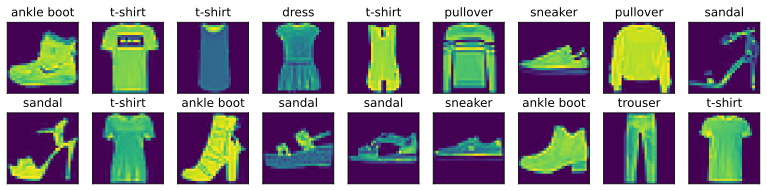

In [230]:
X, y = next(iter(data.DataLoader(mnist_train, batch_size=18)))
show_images(X.reshape(18, 28, 28), 2, 9, titles=get_fashion_mnist_labels(y));

In [231]:
batch_size = 256 #读取小批量

def get_dataloader_workers():  #@save
    """使用4个进程来读取数据"""
    return 4

train_iter = data.DataLoader(mnist_train, batch_size, shuffle=True,
                             num_workers=get_dataloader_workers())

In [232]:
timer = d2l.Timer()
for X, y in train_iter:
    continue
f'{timer.stop():.2f} sec'

'3.29 sec'

### 3.5.3. 整合所有组件

In [233]:
def load_data_fashion_mnist(batch_size, resize=None):  #@save
    """下载Fashion-MNIST数据集，然后将其加载到内存中"""
    trans = [transforms.ToTensor()]
    if resize:
        trans.insert(0, transforms.Resize(resize))
    trans = transforms.Compose(trans)
    mnist_train = torchvision.datasets.FashionMNIST(
        root="../data", train=True, transform=trans, download=True)
    mnist_test = torchvision.datasets.FashionMNIST(
        root="../data", train=False, transform=trans, download=True)
    return (data.DataLoader(mnist_train, batch_size, shuffle=True,
                            num_workers=get_dataloader_workers()),
            data.DataLoader(mnist_test, batch_size, shuffle=False,
                            num_workers=get_dataloader_workers()))

我们通过指定resize参数来测试load_data_fashion_mnist函数的图像大小调整功能：

In [234]:
train_iter, test_iter = load_data_fashion_mnist(batch_size)
for X, y in train_iter:
    print(X.shape, X.dtype, y.shape, y.dtype)
    break

torch.Size([256, 1, 28, 28]) torch.float32 torch.Size([256]) torch.int64


In [235]:
torch.Size([32, 1, 64, 64])   ## 作用？
torch.float32 
torch.Size([32]) 
torch.int64

torch.int64

##  3.6. softmax回归的从零开始实现

In [236]:
import torch
from IPython import display
from d2l import torch as d2l

batch_size = 256 #读取小批量
train_iter, test_iter = load_data_fashion_mnist(batch_size)


### 3.6.1. 初始化模型参数



In [237]:
num_inputs = 784
num_outputs = 10
W = torch.normal(0, 0.01, size=(num_inputs, num_outputs), requires_grad=True)
b = torch.zeros(num_outputs, requires_grad=True)





### 3.6.2. 定义softmax操作  


In [238]:
X = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
X.sum(0, keepdim=True), X.sum(1, keepdim=True)

(tensor([[5., 7., 9.]]),
 tensor([[ 6.],
         [15.]]))

softmax 由三个步骤组成：
- 1. 对每个项求幂（使用exp）。
- 2. 对每一行求和（小批量中每个样本是一行）， 得到每个样本的规范化常数。
- 3. 将每一行除以其规范化常数， 确保结果的和为1。

In [239]:
def softmax(X):
    X_exp = torch.exp(X)
    partition = X_exp.sum(1, keepdim=True)
    return X_exp / partition  # 这里应用了广播机制

X = torch.normal(0, 1, (2, 5)) #生成一个形状为 (2, 5) 的随机张量，其中每个元素都服从均值 0、标准差 1的正态分布。
X_prob = softmax(X)
X_prob, X_prob.sum(1)  # 每行的和为1

#没有对生成的X矩阵中的数字进行检查，可能上溢或下溢

(tensor([[0.1171, 0.0458, 0.2009, 0.3068, 0.3295],
         [0.2523, 0.1380, 0.2455, 0.0818, 0.2824]]),
 tensor([1.0000, 1.0000]))

### 3.6.3 定义模型  


In [240]:
def net(X):
    return softmax(torch.matmul(X.reshape((-1, W.shape[0])), W) + b)

### 3.6.4 定义损失函数  
使用交叉熵损失函数，这可能是深度学习中最常见的损失函数，因为目前分类问题的数量远远超过回归问题的数量。  


In [241]:
#表示有 2 个样本，它们的真实标签分别是：
#第 0 个样本类别是 0
#第 1 个样本类别是 2
y = torch.tensor([0, 2])

# 模型输出的概率矩阵（2 行 3 列）：
# 行 = 样本
# 列 = 类别
# 所以：
# 第 0 行 [0.1, 0.3, 0.6] 是样本0对3个类别的预测概率
# 第 1 行 [0.3, 0.2, 0.5] 是样本1对3个类别的预测概率
y_hat = torch.tensor([[0.1, 0.3, 0.6], [0.3, 0.2, 0.5]])#两个样本在3个类别的预测概率

#是高级索引，等价于分别取
# y_hat[0, y[0]] = y_hat[0,0] = 0.1
# y_hat[1, y[1]] = y_hat[1,2] = 0.5
y_hat[[0, 1], y]  



tensor([0.1000, 0.5000])

In [242]:
# 实现交叉熵损失函数
def cross_entropy(y_hat, y):
    return - torch.log(y_hat[range(len(y_hat)), y])

cross_entropy(y_hat, y)

tensor([2.3026, 0.6931])

### 3.6.5. 分类精度  
分类精度即正确预测数量与总预测数量之比。  
虽然直接优化精度可能很困难（因为精度的计算不可导）， 但精度通常是我们最关心的性能衡量标准，我们在训练分类器时几乎总会关注它。

In [243]:
def accuracy(y_hat, y): #@save
    """计算预测正确的数量"""
    if len(y_hat.shape) > 1 and y_hat.shape[1] > 1:
        y_hat = y_hat.argmax(axis=1) #y_hat的数据类型转换为与y的数据类型一致
    cmp = y_hat.type(y.dtype) == y #预测类别与真实y元素进行比较
    return float(cmp.type(y.dtype).sum())

In [244]:
accuracy(y_hat, y) / len(y)  # 计算预测准确率

0.5

In [245]:
# 评估任意模型net的精度
def evaluate_accuracy(net, data_iter): #@save
    """计算在指定数据集上模型的精度"""
    if isinstance(net, torch.nn.Module):
        net.eval() # 将模型设置为评估模式
    metric = Accumulator(2) # 正确预测数、 预测总数
    with torch.no_grad():
        for X, y in data_iter:
            metric.add(accuracy(net(X), y), y.numel())
    return metric[0] / metric[1]

Accumulator，用于对多个变量进行累加。 在上面的evaluate_accuracy函数中， 我们在Accumulator实例中创建了2个变量， 分别用于存储正确预测的数量和预测的总数量。 当我们遍历数据集时，两者都将随着时间的推移而累加。

In [246]:
class Accumulator: #@save
    """在n个变量上累加"""
    def __init__(self, n):
        self.data = [0.0] * n

    def add(self, *args):
        self.data = [a + float(b) for a, b in zip(self.data, args)]
    def reset(self):
        self.data = [0.0] * len(self.data)
    def __getitem__(self, idx):
        return self.data[idx]

In [247]:
evaluate_accuracy(net, test_iter)

0.1458

### 3.6.6. 训练  

重构训练过程的实现以使其可重复使用

In [248]:
def train_epoch_ch3(net, train_iter, loss, updater): #@save
    """训练模型一个迭代周期（定义见第3章） """
    """将模型设置为训练模式"""
    if isinstance(net, torch.nn.Module):
        net.train()
    # 训练损失总和、训练准确度总和、样本数
    metric = Accumulator(3)
    for X, y in train_iter:
        # 计算梯度并更新参数
        y_hat = net(X)
        l = loss(y_hat, y)

        if isinstance(updater, torch.optim.Optimizer):
            # 使用PyTorch内置的优化器和损失函数
            updater.zero_grad()
            l.mean().backward()
            updater.step()
        else:
            # 使用定制的优化器和损失函数
            l.sum().backward()
            updater(X.shape[0])
        metric.add(float(l.sum()), accuracy(y_hat, y), y.numel())
    # 返回训练损失和训练精度
    return metric[0] / metric[2], metric[1] / metric[2]

定义一个在动画中绘制数据的实用程序类Animator

In [249]:
class Animator:  #@save
    """在动画中绘制数据"""
    def __init__(self, xlabel=None, ylabel=None, legend=None, xlim=None,
                 ylim=None, xscale='linear', yscale='linear',
                 fmts=('-', 'm--', 'g-.', 'r:'), nrows=1, ncols=1,
                 figsize=(3.5, 2.5)):
        # 增量地绘制多条线
        if legend is None:
            legend = []
        d2l.use_svg_display()
        self.fig, self.axes = d2l.plt.subplots(nrows, ncols, figsize=figsize)
        if nrows * ncols == 1:
            self.axes = [self.axes, ]
        # 使用lambda函数捕获参数
        self.config_axes = lambda: d2l.set_axes(
            self.axes[0], xlabel, ylabel, xlim, ylim, xscale, yscale, legend)
        self.X, self.Y, self.fmts = None, None, fmts

    def add(self, x, y):
        # 向图表中添加多个数据点
        if not hasattr(y, "__len__"):
            y = [y]
        n = len(y)
        if not hasattr(x, "__len__"):
            x = [x] * n
        if not self.X:
            self.X = [[] for _ in range(n)]
        if not self.Y:
            self.Y = [[] for _ in range(n)]
        for i, (a, b) in enumerate(zip(x, y)):
            if a is not None and b is not None:
                self.X[i].append(a)
                self.Y[i].append(b)
        self.axes[0].cla()
        for x, y, fmt in zip(self.X, self.Y, self.fmts):
            self.axes[0].plot(x, y, fmt)
        self.config_axes()
        display.display(self.fig)
        display.clear_output(wait=True)

实现一个训练函数， 它会在train_iter访问到的训练数据集上训练一个模型net

In [250]:
def train_ch3(net, train_iter, test_iter, loss, num_epochs, updater):  #@save
    """训练模型（定义见第3章）"""
    animator = Animator(xlabel='epoch', xlim=[1, num_epochs], ylim=[0.3, 0.9],
                        legend=['train loss', 'train acc', 'test acc'])
    for epoch in range(num_epochs):
        train_metrics = train_epoch_ch3(net, train_iter, loss, updater)
        test_acc = evaluate_accuracy(net, test_iter)
        animator.add(epoch + 1, train_metrics + (test_acc,))
    train_loss, train_acc = train_metrics
    assert train_loss < 0.5, train_loss
    assert train_acc <= 1 and train_acc > 0.7, train_acc
    assert test_acc <= 1 and test_acc > 0.7, test_acc

In [251]:
# 使用 3.2节中定义的 小批量随机梯度下降来优化模型的损失函数，设置学习率为0.1。
lr = 0.1

def updater(batch_size):
    return d2l.sgd([W, b], lr, batch_size)

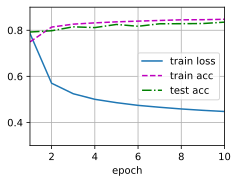

In [252]:
num_epochs = 10
train_ch3(net, train_iter, test_iter, cross_entropy, num_epochs, updater)

### 3.6.7. 预测  

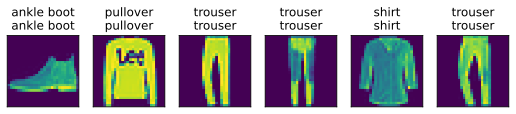

In [253]:
def predict_ch3(net, test_iter, n=6):  #@save
    """预测标签（定义见第3章）"""
    for X, y in test_iter:
        break
    trues = d2l.get_fashion_mnist_labels(y)
    preds = d2l.get_fashion_mnist_labels(net(X).argmax(axis=1))
    titles = [true +'\n' + pred for true, pred in zip(trues, preds)]
    d2l.show_images(
        X[0:n].reshape((n, 28, 28)), 1, n, titles=titles[0:n])

predict_ch3(net, test_iter)

### 3.6.8. 小结
借助softmax回归，我们可以训练多分类的模型。

训练softmax回归循环模型与训练线性回归模型非常相似：先读取数据，再定义模型和损失函数，然后使用优化算法训练模型。大多数常见的深度学习模型都有类似的训练过程。

## 3.7. softmax回归的简洁实现

In [254]:
import torch
from torch import nn
from d2l import torch as d2l

batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)

In [255]:
# PyTorch不会隐式地调整输入的形状。因此，
# 我们在线性层前定义了展平层（flatten），来调整网络输入的形状
net = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))

def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)

net.apply(init_weights);

In [256]:
loss = nn.CrossEntropyLoss(reduction='none')

In [257]:
trainer = torch.optim.SGD(net.parameters(), lr=0.1)

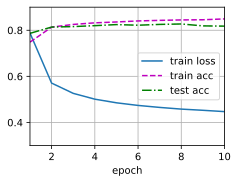

In [258]:
num_epochs = 10
train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)